# House Prices — EDA, Baseline & Pipeline


<div style="background-color:#1e293b;padding:15px;border-left:6px solid #38bdf8;color:#e2e8f0">

<b>Ames housing, rebuilt as a Pipeline.</b> The earlier notebook fit this competition the long way: domain fills by hand, a custom <code>build_matrix()</code>, then <code>LinearRegression</code> on the stacked arrays. This notebook keeps the EDA and those feature choices, then replaces the bookkeeping with one object.

All imputation, scaling, and encoding live inside a <code>ColumnTransformer</code>, with the model on top, fit on a raw training DataFrame. Then one new iteration, a three-way comparison of LinearRegression / Ridge / Lasso in the same skeleton, error analysis on the worst residuals, and a Kaggle submission file.

The competition metric is RMSE of <code>log1p(SalePrice)</code>. Training on the log target optimizes that directly; predictions are reversed with <code>expm1()</code> before submit.

</div>


---
## Step 1: Setup and Loading Data

The same data works locally (this folder, downloaded with the Kaggle CLI) and on Kaggle (`/kaggle/input/...`). We look for `train.csv` in both places.


In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_SEED = 42
TARGET = "SalePrice"


def find_data_dir() -> Path:
    candidates = [
        Path("/kaggle/input/house-prices-advanced-regression-techniques"),
        Path("/kaggle/input/competitions/house-prices-advanced-regression-techniques"),
        Path.cwd(),
        Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd(),
    ]
    for path in candidates:
        if (path / "train.csv").exists():
            return path
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        matches = list(kaggle_root.rglob("train.csv"))
        if matches:
            return matches[0].parent
    raise FileNotFoundError("train.csv not found. Download the competition files into this folder.")


DATA_DIR = find_data_dir()
print(f"Data directory: {DATA_DIR}")

train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")
print(f"Train: {train_raw.shape}   Kaggle test: {test_raw.shape}")
print("Train columns (first 12):", list(train_raw.columns[:12]))


Data directory: /Users/marcus/ml-course/ml-week-6/house_prices_pipeline
Train: (1460, 81)   Kaggle test: (1459, 80)
Train columns (first 12): ['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope']


---
## Step 2: Look at the Data

Ames has 79 features plus `Id` and `SalePrice`. The Kaggle test file has the same features and no price. This is the EDA pass: size, types, missing values, and which number columns move with the target.


In [2]:
print("=== TRAIN ===")
print(train_raw.info())
print("\n=== KAGGLE TEST ===")
print(test_raw.info())


=== TRAIN ===
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  Overa

Numerical columns are already numbers (`GrLivArea`, `YearBuilt`). Categorical columns are text (`Neighborhood`, `HouseStyle`). A few look numeric but are codes — `MSSubClass` is a dwelling type, not a quantity.


In [3]:
numerical_cols = train_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = train_raw.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Numerical columns ({len(numerical_cols)}):", numerical_cols)
print(f"\nCategorical columns ({len(categorical_cols)}):", categorical_cols)


Numerical columns (38): ['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical columns (43): ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional',

Missing values fall into two groups:

1. **"Not present"** — a missing pool or garage usually means the house does not have one
2. **True gaps** — `LotFrontage`, `GarageYrBlt`, a handful of `MasVnrArea` / `Electrical` cells


In [4]:
def missing_summary(df, name):
    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    pct = (missing / len(df) * 100).round(1)
    summary = pd.DataFrame({"count": missing, "pct": pct, "type": df.dtypes[missing.index]})
    print(f"=== Missing values — {name} ({len(missing)} columns with gaps) ===")
    print(summary.to_string())


missing_summary(train_raw, "train")
missing_summary(test_raw, "kaggle test")


=== Missing values — train (19 columns with gaps) ===
              count   pct     type
PoolQC         1453  99.5      str
MiscFeature    1406  96.3      str
Alley          1369  93.8      str
Fence          1179  80.8      str
MasVnrType      872  59.7      str
FireplaceQu     690  47.3      str
LotFrontage     259  17.7  float64
GarageType       81   5.5      str
GarageYrBlt      81   5.5  float64
GarageFinish     81   5.5      str
GarageQual       81   5.5      str
GarageCond       81   5.5      str
BsmtFinType2     38   2.6      str
BsmtExposure     38   2.6      str
BsmtFinType1     37   2.5      str
BsmtCond         37   2.5      str
BsmtQual         37   2.5      str
MasVnrArea        8   0.5  float64
Electrical        1   0.1      str
=== Missing values — kaggle test (33 columns with gaps) ===
              count   pct     type
PoolQC         1456  99.8      str
MiscFeature    1408  96.5      str
Alley          1352  92.7      str
Fence          1169  80.1      str
MasVnrType 

---
## Step 3: What Happens Before the Pipeline

Two kinds of cleaning still belong **before** the pipeline, because they are about the meaning of columns rather than learned statistics:

- Fill "not present" categoricals with `"None"`, map quality ratings to 0–5, cast `MSSubClass` to text, map `CentralAir` to 0/1
- Row-wise features such as `TotalSF` or `HouseAge`, which do not use any training-set statistic

What we do **not** do here: fill `LotFrontage` with a neighborhood median, scale numbers, or one-hot encode. Those fit on training data, so they belong inside the pipeline.


In [5]:
qual_map_5 = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}

ordinal_cols = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond",
    "HeatingQC", "KitchenQual", "FireplaceQu",
    "GarageQual", "GarageCond", "PoolQC",
]

none_cols = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType",
]


def preprocess_manual(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for col in none_cols:
        if col in df.columns:
            df[col] = df[col].fillna("None")
    for col in ordinal_cols:
        if col in df.columns:
            df[col] = df[col].fillna("None").map(qual_map_5).fillna(0).astype(int)
    if "MSSubClass" in df.columns:
        df["MSSubClass"] = df["MSSubClass"].astype(str)
    if "CentralAir" in df.columns:
        df["CentralAir"] = df["CentralAir"].map({"Y": 1, "N": 0})
    return df


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["TotalSF"] = df["TotalBsmtSF"].fillna(0) + df["1stFlrSF"] + df["2ndFlrSF"]
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
    df["TotalBath"] = (
        df["FullBath"] + 0.5 * df["HalfBath"]
        + df["BsmtFullBath"].fillna(0) + 0.5 * df["BsmtHalfBath"].fillna(0)
    )
    df["PorchSF"] = (
        df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"]
    )
    df["HasGarage"] = (df["GarageArea"].fillna(0) > 0).astype(int)
    df["HasBsmt"] = (df["TotalBsmtSF"].fillna(0) > 0).astype(int)
    df["log_GrLivArea"] = np.log1p(df["GrLivArea"])
    df["log_LotArea"] = np.log1p(df["LotArea"])
    df["log_TotalSF"] = np.log1p(df["TotalSF"])
    return df


train_df = engineer_features(preprocess_manual(train_raw))
kaggle_df = engineer_features(preprocess_manual(test_raw))

print(f"Rows: {len(train_df)}   Median SalePrice: ${train_df[TARGET].median():,.0f}")
print("Missing values still in the training frame (handled inside the pipeline):")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])


Rows: 1460   Median SalePrice: $163,000
Missing values still in the training frame (handled inside the pipeline):
LotFrontage    259
MasVnrArea       8
Electrical       1
GarageYrBlt     81
dtype: int64


`TotalSF` and `HouseAge` were in the previous best model. The extra columns (`TotalBath`, `RemodAge`, porch area, log-area) sit in the DataFrame now so the iteration can turn them on. `ColumnTransformer` drops remainder by default, so they do not leak into the previous-best feature list.


In [6]:
for col in ["TotalSF", "HouseAge", "TotalBath", "log_GrLivArea", "log_TotalSF"]:
    corr = train_df[[col, TARGET]].corr().iloc[0, 1]
    print(f"{col:16s} correlation with SalePrice: {corr:.3f}")


TotalSF          correlation with SalePrice: 0.782
HouseAge         correlation with SalePrice: -0.523
TotalBath        correlation with SalePrice: 0.632
log_GrLivArea    correlation with SalePrice: 0.695
log_TotalSF      correlation with SalePrice: 0.762


**Correlation** measures how two number columns move together. `OverallQual`, `GrLivArea`, and `TotalSF` should rank near the top.


Top 12 numerical features correlated with SalePrice:
OverallQual      0.791
TotalSF          0.782
log_TotalSF      0.762
GrLivArea        0.709
log_GrLivArea    0.695
ExterQual        0.683
KitchenQual      0.660
GarageCars       0.640
TotalBath        0.632
GarageArea       0.623
TotalBsmtSF      0.614
1stFlrSF         0.606
Name: SalePrice, dtype: float64


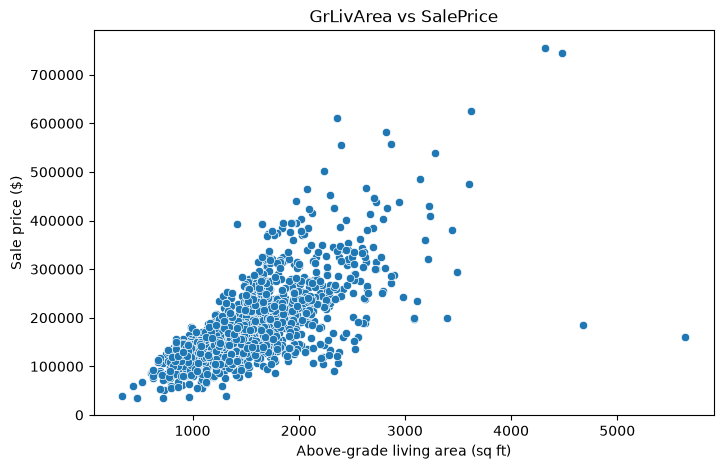

In [7]:
num_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
corr_with_price = (
    train_df[num_cols]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)
print("Top 12 numerical features correlated with SalePrice:")
print(corr_with_price.head(12).round(3))

plt.figure(figsize=(8, 5))
sns.scatterplot(x=train_df["GrLivArea"], y=train_df[TARGET])
plt.title("GrLivArea vs SalePrice")
plt.xlabel("Above-grade living area (sq ft)")
plt.ylabel("Sale price ($)")
plt.show()


SalePrice is right-skewed: most houses sit well below the expensive tail. `log1p` makes the target closer to a bell curve. We reverse predictions with `expm1()` before submitting.


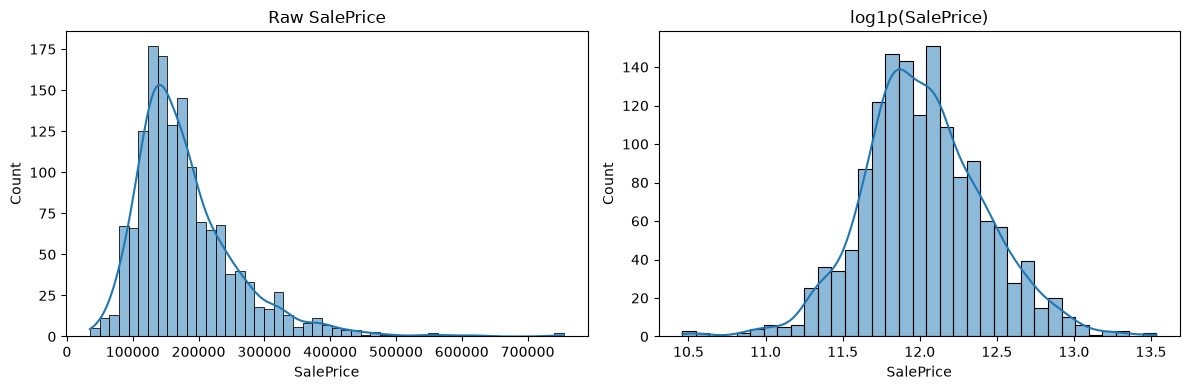

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_df[TARGET], kde=True, ax=axes[0])
axes[0].set_title("Raw SalePrice")
sns.histplot(np.log1p(train_df[TARGET]), kde=True, ax=axes[1])
axes[1].set_title("log1p(SalePrice)")
plt.tight_layout()
plt.show()


---
## Step 4: A Three-Way Split

Comparisons need a place to happen that is not the final local test set, and not Kaggle's `test.csv`:

- **Train** — fit the pipeline (impute, scale, encode, and the regression)
- **Validation** — compare feature sets and later `alpha`, without touching the local test set
- **Local test** — one honest measurement after every decision is locked
- **Kaggle test** — used only at the end, after we refit on all labeled rows

`X` still holds extra columns (`GrLivArea` next to `log_GrLivArea`, features the iteration has not added yet). That is fine: each pipeline only sees the columns it is given.


In [9]:
X = train_df.drop(columns=[TARGET, "Id"])
y = np.log1p(train_df[TARGET])
X_kaggle = kaggle_df.drop(columns=["Id"])

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_SEED
)

print(f"Train: {len(X_train)}   Validation: {len(X_val)}   Local test: {len(X_test)}")
print(f"Mean log-price: train {y_train.mean():.3f}, val {y_val.mean():.3f}, test {y_test.mean():.3f}")

prev_num = [
    "LotFrontage", "LotArea", "OverallQual", "OverallCond", "YearBuilt", "YearRemodAdd",
    "MasVnrArea", "ExterQual", "ExterCond", "BsmtQual", "BsmtCond",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "HeatingQC", "CentralAir",
    "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea",
    "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath",
    "BedroomAbvGr", "KitchenAbvGr", "KitchenQual", "TotRmsAbvGrd",
    "Fireplaces", "FireplaceQu", "GarageYrBlt", "GarageCars", "GarageArea",
    "GarageQual", "GarageCond", "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
    "3SsnPorch", "ScreenPorch", "PoolArea", "PoolQC", "MiscVal", "MoSold", "YrSold",
    "TotalSF", "HouseAge",
]
prev_cat = ["Neighborhood", "MSZoning", "HouseStyle", "MSSubClass"]
baseline_num = ["OverallQual", "GrLivArea", "GarageCars", "TotalSF"]
iter_num = prev_num + [
    "RemodAge", "TotalBath", "PorchSF", "HasGarage", "HasBsmt",
    "log_GrLivArea", "log_LotArea", "log_TotalSF",
]

print(f"\nPrevious-best numeric ({len(prev_num)}) + categorical ({len(prev_cat)})")
print(f"Iteration adds: {[c for c in iter_num if c not in prev_num]}")


Train: 876   Validation: 292   Local test: 292
Mean log-price: train 12.030, val 12.033, test 11.998

Previous-best numeric (48) + categorical (4)
Iteration adds: ['RemodAge', 'TotalBath', 'PorchSF', 'HasGarage', 'HasBsmt', 'log_GrLivArea', 'log_LotArea', 'log_TotalSF']


---
## Step 5: Preprocessing with a Branch Pipeline

A branch of a `ColumnTransformer` can itself be a `Pipeline`. Numeric columns need two steps in a fixed order: impute first, then scale. Categorical columns impute and then one-hot encode.

`LotFrontage` is special: houses on the same street tend to share frontage, so a **neighborhood median** (plus a global fallback) is better than a single city-wide median. That statistic must be learned on training rows only. A small transformer does that as the first pipeline step, before the column branches run.

Wrapping construction in a function means every variant differs only in what we deliberately change.


In [10]:
class GroupMedianImputer(BaseEstimator, TransformerMixin):
    """Impute one column with group medians learned on fit, plus a global fallback."""

    def __init__(self, col="LotFrontage", group_col="Neighborhood"):
        self.col = col
        self.group_col = group_col

    def fit(self, X, y=None):
        X = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        self.group_medians_ = X.groupby(self.group_col)[self.col].median()
        self.global_median_ = X[self.col].median()
        return self

    def transform(self, X):
        X = (X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)).copy()
        filled = X[self.group_col].map(self.group_medians_)
        X[self.col] = X[self.col].fillna(filled).fillna(self.global_median_)
        return X


def make_price_pipeline(num_features, cat_features, model):
    """Impute + scale + encode + model, fit on a raw DataFrame."""
    numeric_branch = Pipeline(steps=[
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    transformers = [("num", numeric_branch, num_features)]
    if cat_features:
        categorical_branch = Pipeline(steps=[
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(sparse_output=False, handle_unknown="ignore")),
        ])
        transformers.append(("cat", categorical_branch, cat_features))
    return Pipeline(steps=[
        ("lotfrontage", GroupMedianImputer()),
        ("preprocess", ColumnTransformer(transformers=transformers)),
        ("model", model),
    ])


def evaluate(pipe, X_eval, y_eval):
    pred = pipe.predict(X_eval)
    return {
        "mae": mean_absolute_error(y_eval, pred),
        "rmse": root_mean_squared_error(y_eval, pred),
        "r2": r2_score(y_eval, pred),
    }


def print_metrics(rows):
    print(f"{'pipeline':<36} {'MAE':>8} {'RMSE':>8} {'R2':>8}")
    for name, metrics in rows:
        print(f"{name:<36} {metrics['mae']:>8.4f} {metrics['rmse']:>8.4f} {metrics['r2']:>8.3f}")


---
## Step 6: Previous Best vs Baseline, Now as Pipelines

The earlier notebook used every numeric column after the ordinal maps, plus four one-hot columns (`Neighborhood`, `MSZoning`, `HouseStyle`, `MSSubClass`), and `LinearRegression` on `log1p(SalePrice)`. A simple baseline uses four strong numeric columns only. Both are rebuilt here as pipelines, fit on the same `X_train` DataFrame, and scored on the same validation split.

The median dummy predicts the same log-price for every house.


In [11]:
median_log = float(y_train.median())
dummy_val = np.full(len(y_val), median_log)
dummy_metrics = {
    "mae": mean_absolute_error(y_val, dummy_val),
    "rmse": root_mean_squared_error(y_val, dummy_val),
    "r2": r2_score(y_val, dummy_val),
}

baseline_pipe = make_price_pipeline(
    baseline_num, [], LinearRegression()
).fit(X_train, y_train)

prev_best_pipe = make_price_pipeline(
    prev_num, prev_cat, LinearRegression()
).fit(X_train, y_train)

print_metrics([
    ("median dummy", dummy_metrics),
    ("baseline (4 numeric)", evaluate(baseline_pipe, X_val, y_val)),
    ("previous best (pipeline)", evaluate(prev_best_pipe, X_val, y_val)),
])

n_features = prev_best_pipe.named_steps["preprocess"].get_feature_names_out().shape[0]
print(f"\nPrevious-best feature count after encoding: {n_features}")


pipeline                                  MAE     RMSE       R2
median dummy                           0.3115   0.3928   -0.003
baseline (4 numeric)                   0.1261   0.1776    0.795
previous best (pipeline)               0.1011   0.1416    0.870

Previous-best feature count after encoding: 100


> **Note:** The median dummy is already a reminder that RMSE here is in log units. A dummy RMSE around 0.39 means typical guesses are off by a factor of about $e^{0.39} \approx 1.5$. The four-feature baseline cuts that roughly in half. The previous-best pipeline goes further (validation RMSE around 0.14) because neighborhood, quality ratings, and basement/garage size carry signal the four columns do not have. That is the model we iterate on.


---
## Step 7: One New Iteration — Extra Area and Bath Features

**What I am changing:** add eight row-wise columns to the numeric branch, and keep `LinearRegression`. Everything else stays put (neighborhood `LotFrontage`, median/most-frequent impute, one-hot of the same four categoricals).

The new columns are the ones that show up again and again in linear Kaggle kernels for this competition:

- `TotalBath`, `RemodAge`, `PorchSF`, `HasGarage`, `HasBsmt` — sums and flags the previous model only had as pieces
- `log_GrLivArea`, `log_LotArea`, `log_TotalSF` — the raw area columns are right-skewed; the log matches the log-price target

**Prediction, before running:** validation RMSE should fall. `TotalSF` already correlated with price at about 0.78, and `log_GrLivArea` is even a little stronger. Bathrooms and remodel age are the other two levers the previous list treated only indirectly.


In [12]:
iter_pipe = make_price_pipeline(
    iter_num, prev_cat, LinearRegression()
).fit(X_train, y_train)

print_metrics([
    ("baseline (4 numeric)", evaluate(baseline_pipe, X_val, y_val)),
    ("previous best (pipeline)", evaluate(prev_best_pipe, X_val, y_val)),
    ("iteration: extra + log area", evaluate(iter_pipe, X_val, y_val)),
])

n_features = iter_pipe.named_steps["preprocess"].get_feature_names_out().shape[0]
print(f"\nIteration feature count after encoding: {n_features}")


pipeline                                  MAE     RMSE       R2
baseline (4 numeric)                   0.1261   0.1776    0.795
previous best (pipeline)               0.1011   0.1416    0.870
iteration: extra + log area            0.0944   0.1356    0.881

Iteration feature count after encoding: 108


> **Note:** The prediction held. Adding the extra columns cuts validation RMSE from about 0.142 to about 0.136, with a matching gain in MAE and R². Eight new columns on ~900 training rows is cheap. Swapping the imputer from median to mean would not be the lever: the remaining numeric gaps are small (`MasVnrArea`, `GarageYrBlt`), and the neighborhood median for `LotFrontage` is already in the pipeline.


---
## Step 8: LinearRegression vs Ridge vs Lasso

The extra-feature pipeline is now the skeleton. The last step is the only thing that changes: plain `LinearRegression`, `Ridge` (L2), or `Lasso` (L1). Same columns, same imputation, same split.

`alpha` is the regularization strength: larger means stronger shrinkage. There is no way to know it in advance, so both Ridge and Lasso get a validation sweep. The local test set stays unused until Step 9.

Lasso's extra property: the L1 penalty drives some weights to **exactly zero**. Those are features the model treats as unimportant given all the others.


### Ridge: validation sweep


   alpha   train RMSE   val RMSE
     0.1       0.1105     0.1355
     0.3       0.1105     0.1352
       1       0.1106     0.1344
       3       0.1112     0.1329
      10       0.1132     0.1310
      30       0.1176     0.1301
     100       0.1254     0.1311

Chosen Ridge alpha (best validation RMSE): 30


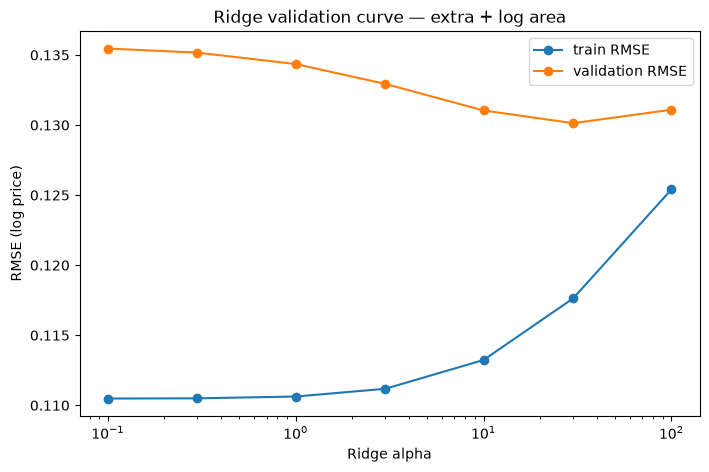

In [13]:
ridge_alphas = [0.1, 0.3, 1, 3, 10, 30, 100]
ridge_train, ridge_val = [], []
print(f"{'alpha':>8} {'train RMSE':>12} {'val RMSE':>10}")
for alpha in ridge_alphas:
    pipe = make_price_pipeline(iter_num, prev_cat, Ridge(alpha=alpha)).fit(X_train, y_train)
    tr = root_mean_squared_error(y_train, pipe.predict(X_train))
    va = root_mean_squared_error(y_val, pipe.predict(X_val))
    ridge_train.append(tr)
    ridge_val.append(va)
    print(f"{alpha:>8} {tr:>12.4f} {va:>10.4f}")

ridge_alpha = ridge_alphas[int(np.argmin(ridge_val))]
print(f"\nChosen Ridge alpha (best validation RMSE): {ridge_alpha}")

plt.figure(figsize=(8, 5))
plt.semilogx(ridge_alphas, ridge_train, "o-", label="train RMSE")
plt.semilogx(ridge_alphas, ridge_val, "o-", label="validation RMSE")
plt.xlabel("Ridge alpha")
plt.ylabel("RMSE (log price)")
plt.title("Ridge validation curve — extra + log area")
plt.legend()
plt.show()


> **Note:** Validation RMSE falls from `alpha=0.1` into a shallow minimum at **`alpha=30`**, then rises at 100. Train and validation stay close: this is shrinkage, not a wild overfit. Any value on that plateau (10–30) is reasonable; we take the minimum, 30.


### Lasso: validation sweep

Same grid idea, smaller alphas: L1 is a stronger penalty than L2 at the same number. `max_iter=50000` is the optimizer budget from the Ridge/Lasso tutorial. The new column is how many weights hit exactly zero.


   alpha   train RMSE   val RMSE       zeroed
  0.0001       0.1107     0.1336    22/108
  0.0003       0.1117     0.1315    28/108
   0.001       0.1164     0.1287    49/108
   0.003       0.1270     0.1294    66/108
    0.01       0.1378     0.1361    85/108
    0.03       0.1518     0.1553    96/108
     0.1       0.2040     0.2100   103/108

Chosen Lasso alpha (best validation RMSE): 0.001


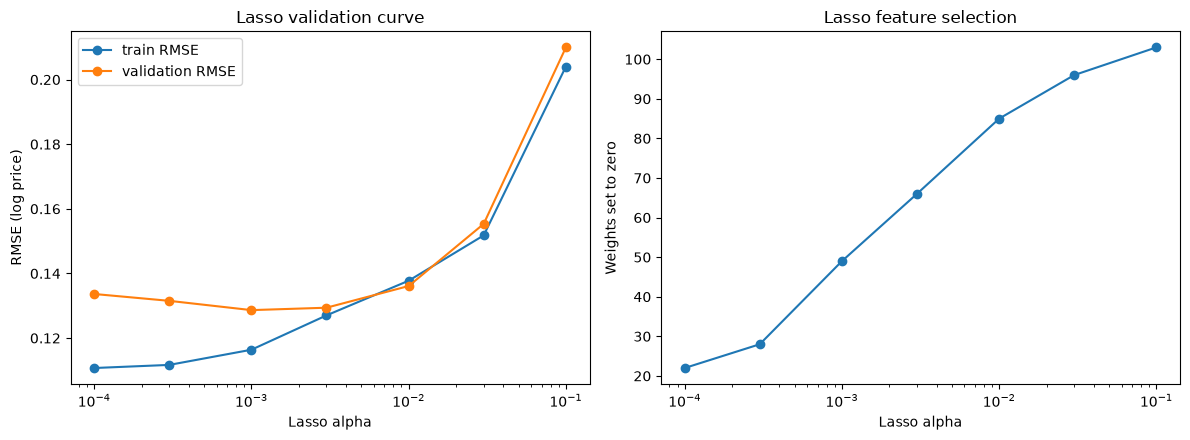

In [14]:
lasso_alphas = [1e-4, 3e-4, 0.001, 0.003, 0.01, 0.03, 0.1]
lasso_train, lasso_val, lasso_zeros = [], [], []
print(f"{'alpha':>8} {'train RMSE':>12} {'val RMSE':>10} {'zeroed':>12}")
for alpha in lasso_alphas:
    pipe = make_price_pipeline(
        iter_num, prev_cat, Lasso(alpha=alpha, max_iter=50000)
    ).fit(X_train, y_train)
    tr = root_mean_squared_error(y_train, pipe.predict(X_train))
    va = root_mean_squared_error(y_val, pipe.predict(X_val))
    coef = pipe.named_steps["model"].coef_
    n_zero = int((coef == 0).sum())
    lasso_train.append(tr)
    lasso_val.append(va)
    lasso_zeros.append(n_zero)
    print(f"{alpha:>8} {tr:>12.4f} {va:>10.4f} {n_zero:>5}/{len(coef)}")

lasso_alpha = lasso_alphas[int(np.argmin(lasso_val))]
print(f"\nChosen Lasso alpha (best validation RMSE): {lasso_alpha}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].semilogx(lasso_alphas, lasso_train, "o-", label="train RMSE")
axes[0].semilogx(lasso_alphas, lasso_val, "o-", label="validation RMSE")
axes[0].set_xlabel("Lasso alpha")
axes[0].set_ylabel("RMSE (log price)")
axes[0].set_title("Lasso validation curve")
axes[0].legend()
axes[1].semilogx(lasso_alphas, lasso_zeros, "o-")
axes[1].set_xlabel("Lasso alpha")
axes[1].set_ylabel("Weights set to zero")
axes[1].set_title("Lasso feature selection")
plt.tight_layout()
plt.show()


> **Note:** The sweet spot is **`alpha=0.001`**: validation RMSE about 0.129, with roughly half the weights zeroed. Weaker Lasso (`1e-4`) is almost unregularized linear regression. Stronger Lasso (`0.01` and up) throws away most columns and underfits. We take 0.001.


Validation comparison of the three, each with its chosen settings. Still no test set.


In [15]:
lr_pipe = make_price_pipeline(iter_num, prev_cat, LinearRegression()).fit(X_train, y_train)
ridge_pipe = make_price_pipeline(iter_num, prev_cat, Ridge(alpha=ridge_alpha)).fit(X_train, y_train)
lasso_pipe = make_price_pipeline(
    iter_num, prev_cat, Lasso(alpha=lasso_alpha, max_iter=50000)
).fit(X_train, y_train)

print("Validation RMSE (extra + log area skeleton):\n")
print_metrics([
    ("LinearRegression", evaluate(lr_pipe, X_val, y_val)),
    (f"Ridge(alpha={ridge_alpha})", evaluate(ridge_pipe, X_val, y_val)),
    (f"Lasso(alpha={lasso_alpha})", evaluate(lasso_pipe, X_val, y_val)),
])


Validation RMSE (extra + log area skeleton):

pipeline                                  MAE     RMSE       R2
LinearRegression                       0.0944   0.1356    0.881
Ridge(alpha=30)                        0.0885   0.1301    0.890
Lasso(alpha=0.001)                     0.0874   0.1287    0.892


### Which features did Lasso set to zero?

At the chosen `alpha`, Lasso's coefficients that are exactly 0 are features it considers unimportant *given the rest of the set*. When several columns say almost the same thing (raw area vs log area, `YearBuilt` vs `HouseAge`), it keeps one and drops the others — not a verdict that the dropped column has no signal on its own.


In [16]:
feature_names = lasso_pipe.named_steps["preprocess"].get_feature_names_out()
coef = lasso_pipe.named_steps["model"].coef_
zero_mask = coef == 0
kept = [(n, c) for n, c in zip(feature_names, coef) if c != 0]
zeroed = feature_names[zero_mask]

print(f"Lasso(alpha={lasso_alpha}) kept {len(kept)} / {len(coef)} features")
print(f"Zeroed {len(zeroed)} features:\n")

zero_num = [n.replace("num__", "") for n in zeroed if n.startswith("num__")]
zero_cat = [n.replace("cat__", "") for n in zeroed if n.startswith("cat__")]
print("Numeric (raw names):")
print(" ", ", ".join(zero_num) if zero_num else "  (none)")
print("\nCategorical dummies:")
for name in zero_cat:
    print(f"  {name}")

print("\nLargest |weights| among features Lasso kept:")
for name, weight in sorted(kept, key=lambda pair: -abs(pair[1]))[:12]:
    print(f"  {name:<42} {weight: .4f}")


Lasso(alpha=0.001) kept 59 / 108 features
Zeroed 49 features:

Numeric (raw names):
  YearBuilt, YearRemodAdd, MasVnrArea, BsmtCond, BsmtFinSF1, 2ndFlrSF, GrLivArea, FullBath, GarageYrBlt, GarageArea, GarageCond, PoolArea, PorchSF, log_GrLivArea

Categorical dummies:
  Neighborhood_Blmngtn
  Neighborhood_BrDale
  Neighborhood_CollgCr
  Neighborhood_IDOTRR
  Neighborhood_MeadowV
  Neighborhood_NAmes
  Neighborhood_NPkVill
  Neighborhood_SWISU
  Neighborhood_Sawyer
  Neighborhood_Timber
  Neighborhood_Veenker
  MSZoning_C (all)
  MSZoning_FV
  MSZoning_RH
  MSZoning_RL
  HouseStyle_1.5Fin
  HouseStyle_1.5Unf
  HouseStyle_1Story
  HouseStyle_2.5Fin
  HouseStyle_2.5Unf
  HouseStyle_2Story
  HouseStyle_SFoyer
  HouseStyle_SLvl
  MSSubClass_120
  MSSubClass_180
  MSSubClass_190
  MSSubClass_30
  MSSubClass_40
  MSSubClass_45
  MSSubClass_50
  MSSubClass_70
  MSSubClass_75
  MSSubClass_80
  MSSubClass_85
  MSSubClass_90

Largest |weights| among features Lasso kept:
  num__log_TotalSF         

> **Note:** The zeros cluster in two places.
>
> **Redundant numbers.** Lasso drops `GrLivArea`, `log_GrLivArea`, `YearBuilt`, `YearRemodAdd`, `FullBath`, `GarageArea`, `GarageYrBlt`, and `PorchSF`. It keeps `log_TotalSF` (largest weight), `HouseAge`, `TotalBath`, and `GarageCars`. Same information, fewer columns: the correlated-features caveat from the tutorial.
>
> **Rare one-hots.** Most `MSSubClass` codes, most `HouseStyle` codes, and several neighborhoods (NAmes, CollgCr, IDOTRR, Sawyer, …) go to zero. The dummies it keeps are the ones with a distinct price story: StoneBr, Crawfor, NridgHt, NoRidge, Edwards.
>
> Read the kept set as "enough to predict well," not as "the true causes." 


---
## Step 9: Held-out RMSE for All Three

Alphas are locked (`Ridge` 30, `Lasso` 0.001). Retrain each pipeline on train + validation and score **once** on the local test set. RMSE of log price is the competition metric.


Local test-set RMSE (log1p SalePrice):

pipeline                                  MAE     RMSE       R2
median dummy                           0.3350   0.4323   -0.001
baseline (4 numeric)                   0.1283   0.1803    0.826
previous best (pipeline)               0.0936   0.1317    0.907
LinearRegression                       0.0872   0.1235    0.918
Ridge(alpha=30)                        0.0880   0.1329    0.905
Lasso(alpha=0.001)                     0.0885   0.1336    0.904


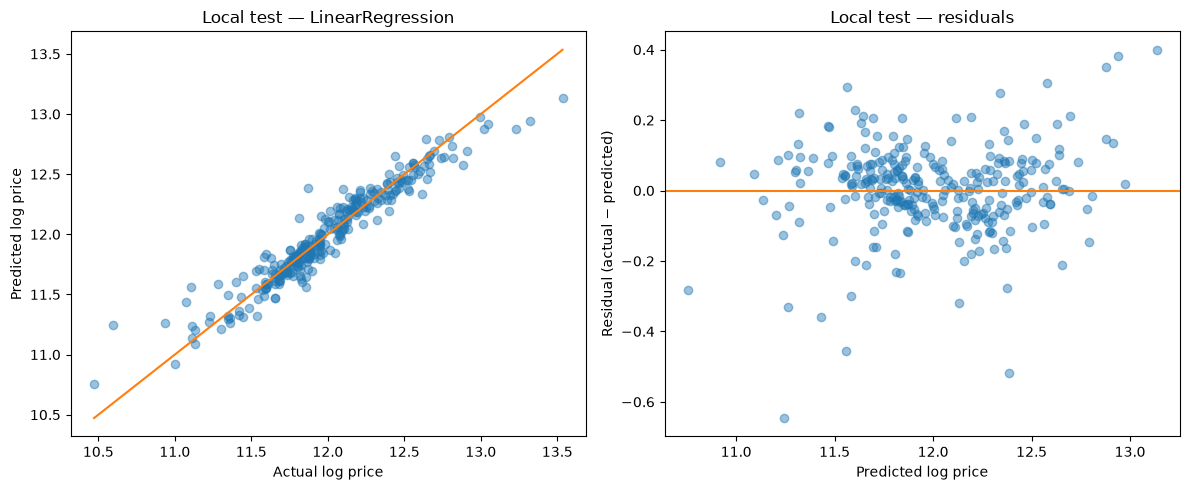

In [17]:
final_lr = make_price_pipeline(
    iter_num, prev_cat, LinearRegression()
).fit(X_trainval, y_trainval)
final_ridge = make_price_pipeline(
    iter_num, prev_cat, Ridge(alpha=ridge_alpha)
).fit(X_trainval, y_trainval)
final_lasso = make_price_pipeline(
    iter_num, prev_cat, Lasso(alpha=lasso_alpha, max_iter=50000)
).fit(X_trainval, y_trainval)

final_dummy = np.full(len(y_test), float(y_trainval.median()))
final_baseline = make_price_pipeline(
    baseline_num, [], LinearRegression()
).fit(X_trainval, y_trainval)
final_prev_best = make_price_pipeline(
    prev_num, prev_cat, LinearRegression()
).fit(X_trainval, y_trainval)

print("Local test-set RMSE (log1p SalePrice):\n")
print_metrics([
    ("median dummy", {
        "mae": mean_absolute_error(y_test, final_dummy),
        "rmse": root_mean_squared_error(y_test, final_dummy),
        "r2": r2_score(y_test, final_dummy),
    }),
    ("baseline (4 numeric)", evaluate(final_baseline, X_test, y_test)),
    ("previous best (pipeline)", evaluate(final_prev_best, X_test, y_test)),
    ("LinearRegression", evaluate(final_lr, X_test, y_test)),
    (f"Ridge(alpha={ridge_alpha})", evaluate(final_ridge, X_test, y_test)),
    (f"Lasso(alpha={lasso_alpha})", evaluate(final_lasso, X_test, y_test)),
])

# Held-out RMSE picked LinearRegression; use it for residuals and submit
final_pipe = final_lr
y_test_pred = final_pipe.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, y_test_pred, alpha=0.45)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, color="C1")
axes[0].set_xlabel("Actual log price")
axes[0].set_ylabel("Predicted log price")
axes[0].set_title("Local test — LinearRegression")

resid = y_test - y_test_pred
axes[1].scatter(y_test_pred, resid, alpha=0.45)
axes[1].axhline(0, color="C1")
axes[1].set_xlabel("Predicted log price")
axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Local test — residuals")
plt.tight_layout()
plt.show()


> **Note:** On the held-out split, **LinearRegression wins** (RMSE about 0.123 vs 0.133 Ridge and 0.134 Lasso). Validation had preferred Lasso by a few thousandths — with 292 validation rows that gap is noise, and it did not transfer. Regularization was not the lever here: ~900 rows and ~100 well-scaled columns is closer to the car-price tutorial, where Ridge, Lasso, and OLS landed together.
>
> Error analysis and the Kaggle file therefore keep extra-feature `LinearRegression`. The residual plot is the next question: *which* houses sit far above or below the line.


---
## Step 10: Error Analysis — Read the Worst Residuals

`X_test` was never converted into an anonymous numeric matrix, so attaching predictions to real houses is one line.

- **Worst underpredictions:** houses that sold for much more than the model expected (largest positive residual, `actual − predicted`)
- **Worst overpredictions:** houses that sold for much less than the model expected (largest negative residual)


In [18]:
results = X_test.copy()
results["actual_log"] = y_test.values
results["pred_log"] = final_pipe.predict(X_test)
results["resid"] = results["actual_log"] - results["pred_log"]
results["actual_price"] = np.expm1(results["actual_log"])
results["pred_price"] = np.expm1(results["pred_log"])

show_cols = [
    "Neighborhood", "OverallQual", "GrLivArea", "TotalSF", "HouseAge",
    "GarageCars", "SaleCondition", "actual_price", "pred_price", "resid",
]

worst_under = results.sort_values("resid", ascending=False).head(10)
worst_over = results.sort_values("resid").head(10)

print("Worst underpredictions (sold for more than the model thought):")
print(worst_under[show_cols].to_string())
print("\nWorst overpredictions (sold for less than the model thought):")
print(worst_over[show_cols].to_string())


Worst underpredictions (sold for more than the model thought):
     Neighborhood  OverallQual  GrLivArea  TotalSF  HouseAge  GarageCars SaleCondition  actual_price     pred_price     resid
691       NoRidge           10       4316     6760        13           3        Normal      755000.0  506191.148102  0.399803
898       NridgHt            9       2364     4694         1           3       Partial      611657.0  416875.269272  0.383384
1046      StoneBr            9       2868     4860         1           3       Partial      556581.0  391486.975433  0.351860
774       NridgHt            8       1973     3908         1           3       Partial      395000.0  290693.874780  0.306614
277       Gilbert            4        864     1728        59           2        Normal      141000.0  104998.034387  0.294816
322       SawyerW            7       2730     4232        21           2        Normal      301000.0  228274.858737  0.276559
669       Crawfor            4       1180     1880     

In [19]:
def compare_to_test(name, group):
    print(f"{name}  (n={len(group)})")
    print(f"  mean OverallQual:   {group['OverallQual'].mean():.2f}   "
          f"(test {results['OverallQual'].mean():.2f})")
    print(f"  mean GrLivArea:     {group['GrLivArea'].mean():.0f}   "
          f"(test {results['GrLivArea'].mean():.0f})")
    print(f"  mean HouseAge:      {group['HouseAge'].mean():.1f}   "
          f"(test {results['HouseAge'].mean():.1f})")
    print(f"  mean actual price:  ${group['actual_price'].mean():,.0f}   "
          f"(test ${results['actual_price'].mean():,.0f})")
    print("  Neighborhood:",
          group["Neighborhood"].value_counts().head(3).to_dict())
    print("  SaleCondition:",
          group["SaleCondition"].value_counts().to_dict())
    print()


print("Compared with the rest of the local test set:\n")
compare_to_test("Worst 10 underpredictions", worst_under)
compare_to_test("Worst 10 overpredictions", worst_over)
compare_to_test("Full local test set", results)


Compared with the rest of the local test set:

Worst 10 underpredictions  (n=10)
  mean OverallQual:   6.80   (test 6.01)
  mean GrLivArea:     2207   (test 1468)
  mean HouseAge:      35.0   (test 35.3)
  mean actual price:  $354,451   (test $178,840)
  Neighborhood: {'NoRidge': 2, 'NridgHt': 2, 'StoneBr': 1}
  SaleCondition: {'Normal': 6, 'Partial': 3, 'Abnorml': 1}

Worst 10 overpredictions  (n=10)
  mean OverallQual:   4.70   (test 6.01)
  mean GrLivArea:     1202   (test 1468)
  mean HouseAge:      56.2   (test 35.3)
  mean actual price:  $90,876   (test $178,840)
  Neighborhood: {'IDOTRR': 3, 'OldTown': 2, 'ClearCr': 1}
  SaleCondition: {'Normal': 4, 'Abnorml': 2, 'Alloca': 2, 'Partial': 1, 'Family': 1}

Full local test set  (n=292)
  mean OverallQual:   6.01   (test 6.01)
  mean GrLivArea:     1468   (test 1468)
  mean HouseAge:      35.3   (test 35.3)
  mean actual price:  $178,840   (test $178,840)
  Neighborhood: {'NAmes': 44, 'CollgCr': 35, 'OldTown': 22}
  SaleCondition: {'

> **Note:** The two error types are almost opposite profiles.
>
> The ten worst **underpredictions** are large, high-quality houses (mean `OverallQual` about 7 vs 6 on the test set, living area about 2,200 vs 1,470 sq ft) in NoRidge / NridgHt / StoneBr. Several are `Partial` sales — new homes sold before they are finished. Actual prices sit around $360k versus $179k on the test set. The model has the right direction (quality and size push the price up) but not enough for the luxury tail.
>
> The ten worst **overpredictions** are older, lower-quality houses (mean quality about 5, age about 56 vs 35 years) clustered in IDOTRR and OldTown, often `Abnorml` or other unusual sale conditions. They sold around $90k. The model prices them like typical Ames houses of that size; the sale itself was not typical.
>
> Both patterns are a hypothesis generator. A next iteration could add `SaleCondition` to the categorical branch, or an interaction such as `OverallQual × GrLivArea` for the luxury tail. The two famous Edwards outliers (`GrLivArea` above 4,000 with a low price) are the other known lever on this dataset — dropping them from training is a common Kaggle step, and it belongs in a train-only filter, not a silent edit of the test set.


---
## Step 11: Refit on All Labeled Rows and Submit

The local split was only for deciding. Held-out RMSE picked extra-feature `LinearRegression`. For the Kaggle file we refit that pipeline on every row in `train.csv`, predict `test.csv`, reverse the log, and clip negatives to zero.


In [20]:
submit_pipe = make_price_pipeline(
    iter_num, prev_cat, LinearRegression()
).fit(X, y)

y_kaggle = np.expm1(submit_pipe.predict(X_kaggle))
y_kaggle = np.maximum(y_kaggle, 0)

submission = pd.DataFrame({
    "Id": test_raw["Id"],
    "SalePrice": y_kaggle,
})
out_path = Path("house_prices_submission.csv")
submission.to_csv(out_path, index=False)
print(f"Wrote {out_path.resolve()}  ({len(submission)} rows)")
print(submission.head())
print(f"\nPredicted SalePrice: min ${submission['SalePrice'].min():,.0f}  "
      f"median ${submission['SalePrice'].median():,.0f}  "
      f"max ${submission['SalePrice'].max():,.0f}")


Wrote /Users/marcus/ml-course/ml-week-6/house_prices_pipeline/house_prices_submission.csv  (1459 rows)
     Id      SalePrice
0  1461  122230.611379
1  1462  158836.459653
2  1463  175034.856351
3  1464  190053.508443
4  1465  211212.336024

Predicted SalePrice: min $37,675  median $160,348  max $490,147


To send the file from this folder (requires a configured Kaggle CLI):

```bash
kaggle competitions submit -c house-prices-advanced-regression-techniques \
  -f house_prices_submission.csv \
  -m "pipeline extra+log LinearRegression"
```


---
## Pipeline section — what changed

1. **One object** — neighborhood `LotFrontage`, imputation, scaling, and encoding sit inside a `Pipeline`; the model sits on top; `.fit(X_train, y_train)` is called on the raw DataFrame.
2. **Previous best, rebuilt** — same numeric columns and four categoricals as the hand-rolled `build_matrix()` model.
3. **One iteration** — extra area/bath columns beat the previous best and the four-feature baseline.
4. **Three models, same skeleton** — LinearRegression, Ridge (`alpha=30`), and Lasso (`alpha=0.001`), alphas chosen on validation. Held-out RMSE: LinearRegression 0.123, Ridge 0.133, Lasso 0.134. OLS keeps the file.
5. **Lasso zeros** — about half the weights: redundant raw area/year/bath/garage columns (it kept the log and the totals) and rare neighborhood / `MSSubClass` dummies.
6. **Error analysis** — the worst misses are luxury / new-construction homes the model underprices, and unusual sales in older IDOTRR / OldTown houses it overprices.
